# dispertorch — usage examples

This notebook walks through the main features of **dispertorch**:
differentiable refractive-index dispersion models built on `torch.nn.Module`.

Sections:
1. Quick start — gold n, k from a preset
2. Permittivity is the primitive
3. Single-oscillator models (Lorentz, Drude, Tauc-Lorentz)
4. Building materials by composition
5. Material-presets gallery
6. Gradient-based fitting ← the headline use-case
7. Persistence with `state_dict`


In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from dispertorch import (
    ConstantEps, ConstantIndex, Drude, Lorentz, TaucLorentz, material
)
from dispertorch.oscillator import _HC_EV_NM

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True,
                     'grid.alpha': 0.3, 'lines.linewidth': 1.8})


## 1  Quick start — gold n, k

`material('Au')` returns a fully-built `Composite` (Rakić 1998 Lorentz-Drude).
Wavelength is always in **nm**; `nk()` returns real and imaginary parts in one call.


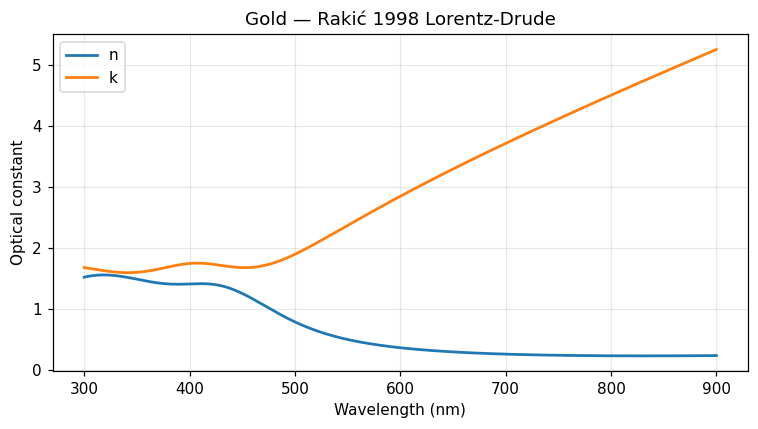

In [2]:
au = material('Au')
wl = torch.linspace(300, 900, 400)   # nm

n, k = au.nk(wl)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(wl, n.detach(), label='n')
ax.plot(wl, k.detach(), label='k')
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Optical constant')
ax.set_title('Gold — Rakić 1998 Lorentz-Drude')
ax.legend()
plt.tight_layout()
plt.show()


## 2  Permittivity is the primitive

All quantities (n, k, index) are derived from `permittivity(wl)`, which returns
complex ε = ε′ + iε″.  The sign convention is **ε″ ≥ 0** for absorbing media
(`exp(-iωt)`, so `Im(√ε) = k ≥ 0` follows from the principal square root).


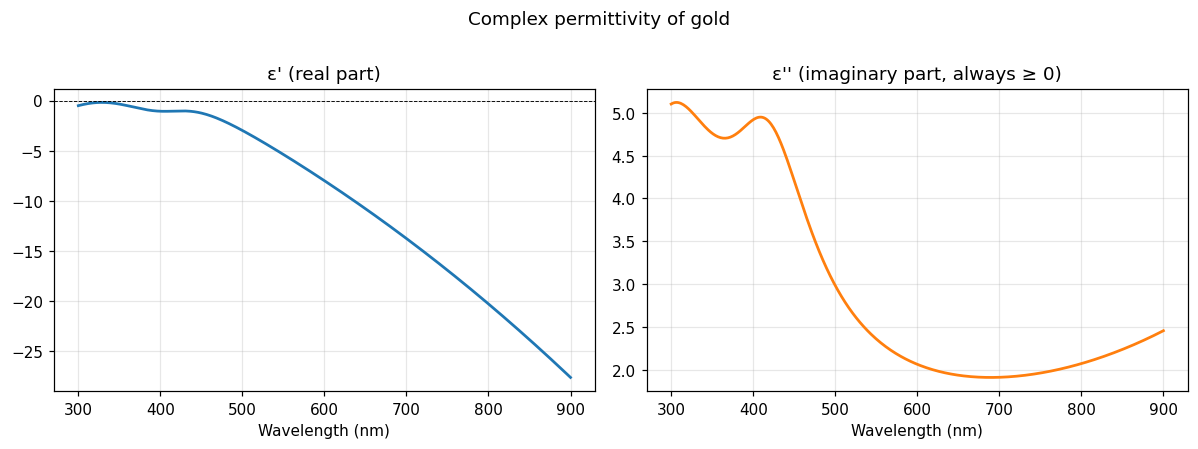

In [3]:
eps = au.permittivity(wl).detach()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(wl, eps.real)
axes[0].axhline(0, color='k', lw=0.6, ls='--')
axes[0].set_title("ε' (real part)")
axes[1].plot(wl, eps.imag, color='C1')
axes[1].set_title("ε'' (imaginary part, always ≥ 0)")
for ax in axes:
    ax.set_xlabel('Wavelength (nm)')
plt.suptitle('Complex permittivity of gold', y=1.01)
plt.tight_layout()
plt.show()


## 3  Single-oscillator models

### 3a  Lorentz — harmonic oscillator

ε(E) = A / (ω₀² − E² − iγE).  ε″ ≥ 0 for A, γ > 0; peaks near ω₀.


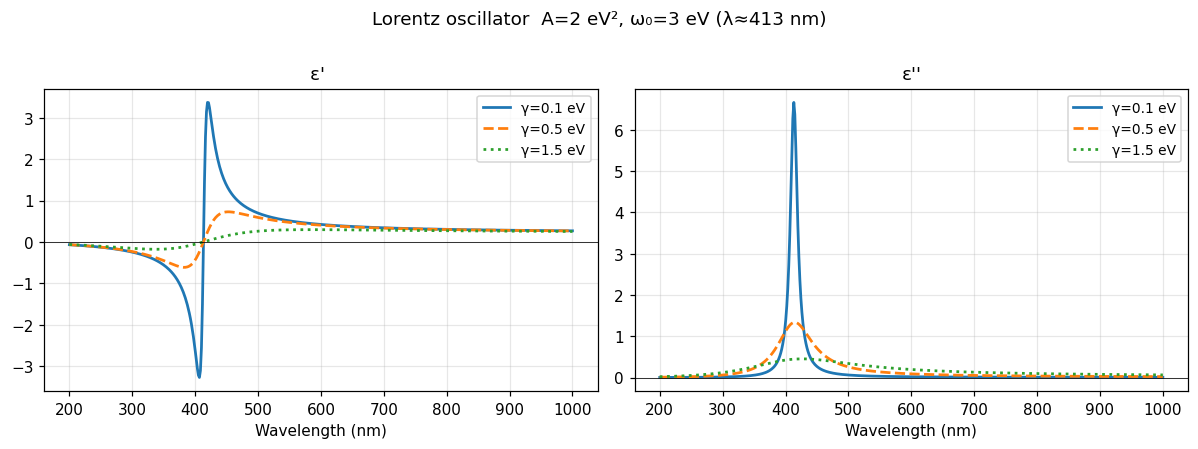

In [4]:
wl = torch.linspace(200, 1000, 500)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for gamma, ls in [(0.1, '-'), (0.5, '--'), (1.5, ':')]:
    m = Lorentz(A=2.0, omega_0=3.0, gamma=gamma)
    eps = m.permittivity(wl).detach()
    lbl = f'γ={gamma} eV'
    axes[0].plot(wl, eps.real, ls=ls, label=lbl)
    axes[1].plot(wl, eps.imag, ls=ls, label=lbl)

for ax in axes:
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xlabel('Wavelength (nm)')
    ax.legend(fontsize=9)
axes[0].set_title("ε' ")
axes[1].set_title("ε''")
plt.suptitle('Lorentz oscillator  A=2 eV², ω₀=3 eV (λ≈413 nm)', y=1.01)
plt.tight_layout()
plt.show()


### 3b  Drude — free electrons

ε(E) = −ωp² / (E² + iγE).  ε′ < 0 everywhere → metallic (n < 1, large k).


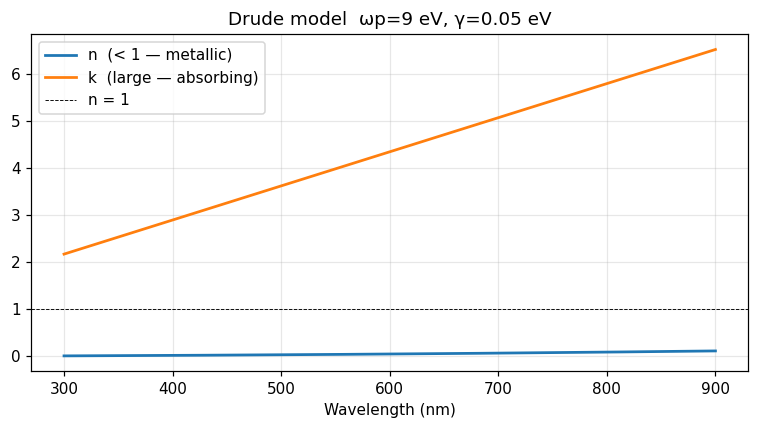

In [5]:
wl = torch.linspace(300, 900, 400)
m_drude = Drude(omega_p=9.0, gamma=0.05)
n_dr, k_dr = m_drude.nk(wl)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(wl, n_dr.detach(), label='n  (< 1 — metallic)')
ax.plot(wl, k_dr.detach(), label='k  (large — absorbing)')
ax.axhline(1, color='k', lw=0.6, ls='--', label='n = 1')
ax.set_xlabel('Wavelength (nm)')
ax.legend()
ax.set_title('Drude model  ωp=9 eV, γ=0.05 eV')
plt.tight_layout()
plt.show()


### 3c  Tauc-Lorentz — amorphous semiconductors

ε₂(E) is a Lorentz oscillator multiplied by the Tauc density of states,
forced to **zero below the optical gap E_g**.  ε₁(E) follows via the
closed-form Kramers-Kronig transform (Jellison & Modine 1996).


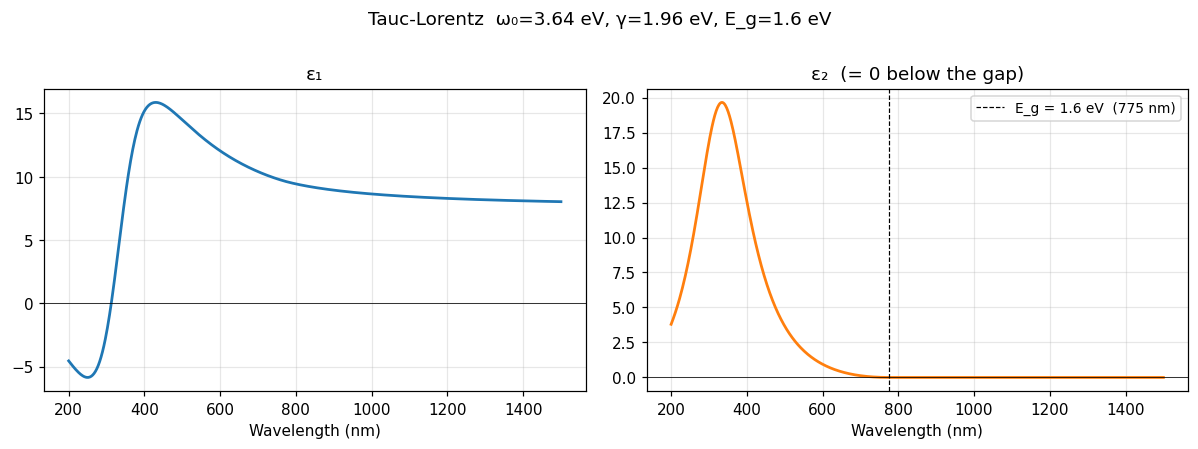

In [6]:
wl = torch.linspace(200, 1500, 700)
m_tl = TaucLorentz(A=122.0, omega_0=3.64, gamma=1.96, E_g=1.6)  # a-Si:H-like
eps  = m_tl.permittivity(wl).detach()

wl_gap = _HC_EV_NM / 1.6   # ≈ 775 nm

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(wl, eps.real)
axes[0].set_title('ε₁')
axes[1].plot(wl, eps.imag, color='C1')
axes[1].axvline(wl_gap, color='k', lw=0.8, ls='--',
                label=f'E_g = 1.6 eV  ({wl_gap:.0f} nm)')
axes[1].set_title('ε₂  (= 0 below the gap)')
axes[1].legend(fontsize=9)
for ax in axes:
    ax.set_xlabel('Wavelength (nm)')
    ax.axhline(0, color='k', lw=0.5)
plt.suptitle('Tauc-Lorentz  ω₀=3.64 eV, γ=1.96 eV, E_g=1.6 eV', y=1.01)
plt.tight_layout()
plt.show()


## 4  Building materials by composition

Models add with `+` (or `sum([...])`).  The typical pattern for a bound-electron
dielectric is: `ConstantEps(ε_∞) + Lorentz(...) + Lorentz(...) + ...`

Nested composites are flattened — `a + b + c` produces a single
`Composite([a, b, c])`, not `Composite([Composite([a, b]), c])`.


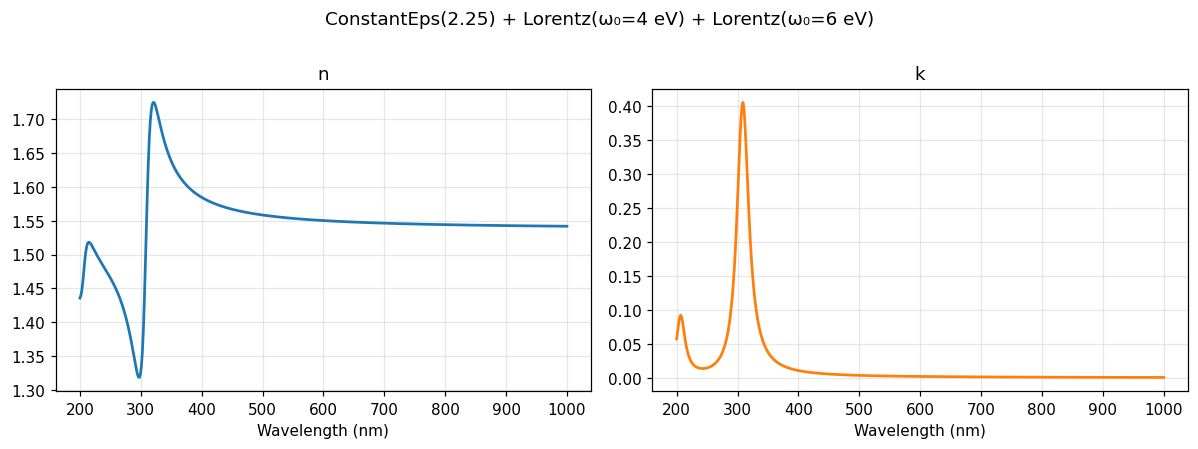

Number of terms in composite: 3


In [7]:
eps_inf = ConstantEps(2.25)
lo1 = Lorentz(A=1.5, omega_0=4.0, gamma=0.3)
lo2 = Lorentz(A=0.8, omega_0=6.0, gamma=0.5)

# Two equivalent ways to compose:
model_a = eps_inf + lo1 + lo2
model_b = sum([eps_inf, lo1, lo2])

wl = torch.linspace(200, 1000, 500)
assert torch.allclose(model_a.permittivity(wl), model_b.permittivity(wl))

n_c, k_c = model_a.nk(wl)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(wl, n_c.detach())
axes[1].plot(wl, k_c.detach(), color='C1')
for ax, lbl in zip(axes, ['n', 'k']):
    ax.set_xlabel('Wavelength (nm)')
    ax.set_title(lbl)
plt.suptitle('ConstantEps(2.25) + Lorentz(ω₀=4 eV) + Lorentz(ω₀=6 eV)', y=1.01)
plt.tight_layout()
plt.show()

print('Number of terms in composite:', len(model_a.terms))  # 3 (flat)


## 5  Material-presets gallery

Four common metals from the Rakić et al. (1998) Lorentz-Drude table.
Each is loaded as a `Composite` and is immediately ready for fitting.


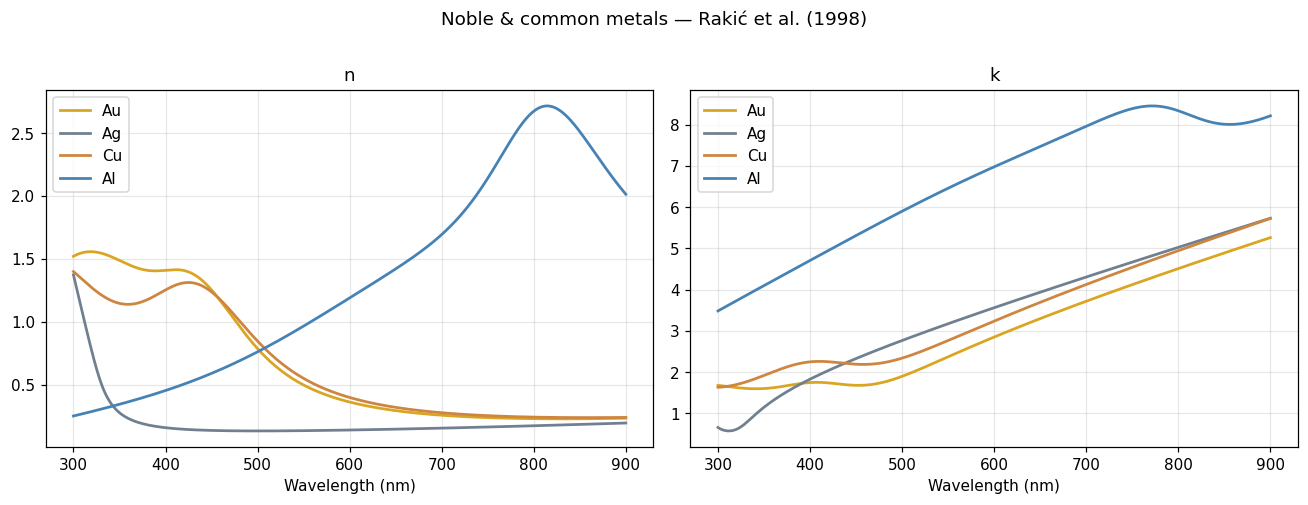

In [8]:
metals  = ['Au', 'Ag', 'Cu', 'Al']
palette = {'Au': 'goldenrod', 'Ag': 'slategray', 'Cu': 'peru', 'Al': 'steelblue'}
wl = torch.linspace(300, 900, 400)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for metal in metals:
    m = material(metal)
    n_m, k_m = m.nk(wl)
    c = palette[metal]
    axes[0].plot(wl, n_m.detach(), label=metal, color=c)
    axes[1].plot(wl, k_m.detach(), label=metal, color=c)

for ax, lbl in zip(axes, ['n', 'k']):
    ax.set_xlabel('Wavelength (nm)')
    ax.set_title(lbl)
    ax.legend()
plt.suptitle('Noble & common metals — Rakić et al. (1998)', y=1.01)
plt.tight_layout()
plt.show()


## 6  Gradient-based fitting

This is the core use-case: treat dispersion coefficients as `nn.Parameter` values
and optimise them to match measured n, k data.

**Setup:** synthesise a known target from `ConstantEps(1.5) + Lorentz(A=2, ω₀=2.5, γ=0.3)`,
then fit a fresh model starting from perturbed initial values.


In [9]:
# Ground-truth model (defines the synthetic target)
true_model = ConstantEps(1.5) + Lorentz(A=2.0, omega_0=2.5, gamma=0.3)
wl_fit = torch.linspace(300, 800, 100)

with torch.no_grad():
    n_target, k_target = true_model.nk(wl_fit)

# Fit model — all four coefficients are trainable nn.Parameters
fit_model = ConstantEps(nn.Parameter(torch.tensor(1.0))) + Lorentz(
    A=nn.Parameter(torch.tensor(1.0)),
    omega_0=nn.Parameter(torch.tensor(2.0)),
    gamma=nn.Parameter(torch.tensor(0.5)),
)
optimizer = torch.optim.Adam(fit_model.parameters(), lr=1e-2)

losses = []
for step in range(800):
    optimizer.zero_grad()
    n_pred, k_pred = fit_model.nk(wl_fit)
    loss = ((n_pred - n_target)**2 + (k_pred - k_target)**2).mean()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print(f'Final loss: {losses[-1]:.2e}')


Final loss: 9.76e-14


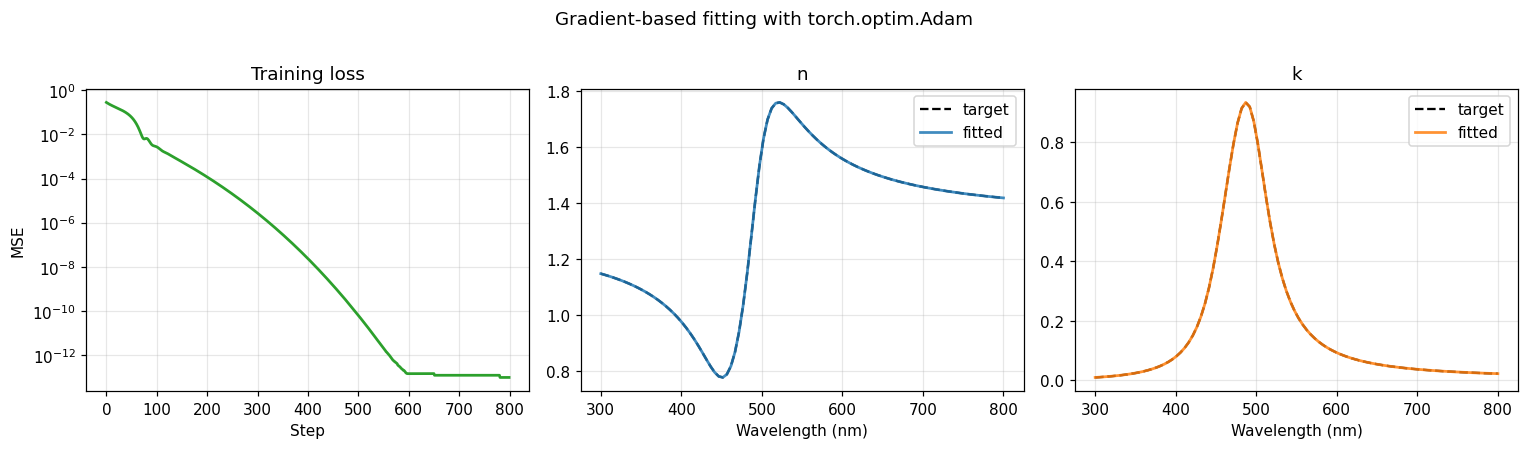

In [10]:
# ── Plots ─────────────────────────────────────────────────────────────────────
with torch.no_grad():
    n_fit, k_fit = fit_model.nk(wl_fit)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Loss curve
axes[0].semilogy(losses, color='C2')
axes[0].set_xlabel('Step')
axes[0].set_ylabel('MSE')
axes[0].set_title('Training loss')

# n
axes[1].plot(wl_fit, n_target, 'k--', lw=1.5, label='target')
axes[1].plot(wl_fit, n_fit,    color='C0',   label='fitted', alpha=0.85)
axes[1].set_xlabel('Wavelength (nm)')
axes[1].set_title('n')
axes[1].legend()

# k
axes[2].plot(wl_fit, k_target, 'k--', lw=1.5, label='target')
axes[2].plot(wl_fit, k_fit,    color='C1',   label='fitted', alpha=0.85)
axes[2].set_xlabel('Wavelength (nm)')
axes[2].set_title('k')
axes[2].legend()

plt.suptitle('Gradient-based fitting with torch.optim.Adam', y=1.01)
plt.tight_layout()
plt.show()


In [11]:
# ── Recovered parameters ───────────────────────────────────────────────────────
eps_inf_r = fit_model.terms[0].eps_re.item()
A_r       = fit_model.terms[1].A.item()
om0_r     = fit_model.terms[1].omega_0.item()
gam_r     = fit_model.terms[1].gamma.item()

print(f"{'Parameter':12} {'True':>10} {'Fitted':>10} {'Error':>10}")
print('-' * 46)
for name, true_v, fit_v in [
    ('eps_inf',   1.5, eps_inf_r),
    ('A (eV²)',   2.0, A_r),
    ('omega_0',   2.5, om0_r),
    ('gamma',     0.3, gam_r),
]:
    print(f"{name:12} {true_v:>10.4f} {fit_v:>10.4f} {abs(fit_v-true_v):>10.2e}")


Parameter          True     Fitted      Error
----------------------------------------------
eps_inf          1.5000     1.5000   5.96e-07
A (eV²)          2.0000     2.0000   1.31e-06
omega_0          2.5000     2.5000   0.00e+00
gamma            0.3000     0.3000   2.26e-07


## 7  Persistence and devices

Because every model is an `nn.Module`, the full PyTorch infrastructure applies:
- `state_dict()` / `load_state_dict()` for serialisation
- `.to(dtype=torch.float64)` or `.to('cuda')` for device/dtype moves


In [14]:
import io

# Serialise
buf = io.BytesIO()
torch.save(fit_model.state_dict(), buf)
buf.seek(0)

# Rebuild (buffers instead of parameters — load_state_dict fills them in)
reloaded = ConstantEps(0.0) + Lorentz(0.0, 1.0, 1.0)
reloaded.load_state_dict(torch.load(buf, weights_only=True))

with torch.no_grad():
    n_rel, k_rel = reloaded.nk(wl_fit)

print('Max |n_fit - n_reloaded|:', (n_fit - n_rel).abs().max().item())
print('All close:', torch.allclose(n_fit, n_rel))

# dtype upgrade
reloaded64 = reloaded.to(dtype=torch.float64)
wl64 = wl_fit.double()
n64, k64 = reloaded64.nk(wl64)
print('dtype of n64:', n64.dtype)   # float64


Max |n_fit - n_reloaded|: 0.0
All close: True
dtype of n64: torch.float64
